# Exploratory data analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/cleaned/books_cleaned.csv")
df.head()

,title,category,book_url,image_url,description,image_path,title_description
0,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,Title: Private Paris (Private #10) Description...
1,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,"Title: We Love You, Charlie Freeman Descriptio..."
2,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg,Title: Thirst Description: On a searing summer...
3,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg,Title: The Murder That Never Was (Forensic Ins...
4,Tuesday Nights in 1980,Fiction,https://books.toscrape.com/catalogue/tuesday-n...,https://books.toscrape.com/media/cache/6b/da/6...,"“In one sentence, Ms. Prentiss captures a sens...",images/book_5.jpg,Title: Tuesday Nights in 1980 Description: “In...


### Books Category Analysis

In [3]:
print(df["category"].value_counts())

category
Nonfiction    109
Fiction        64
Name: count, dtype: int64


In [4]:
print("Percentage of books category:")
print((df["category"].value_counts(normalize=True) * 100).round(1))

Percentage of books category:
category
Nonfiction    63.0
Fiction       37.0
Name: proportion, dtype: float64


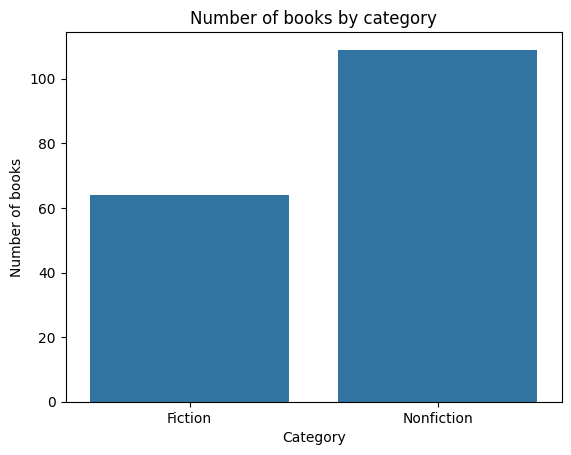

In [5]:
sns.countplot( x="category", data=df, order=["Fiction", "Nonfiction"])
plt.title("Number of books by category")
plt.xlabel("Category")
plt.ylabel("Number of books")
plt.show()

In [6]:
df["title_length"] = df["title"].str.len()
df["description_length"] = df["description"].str.len()

### Books Tittle Analysis


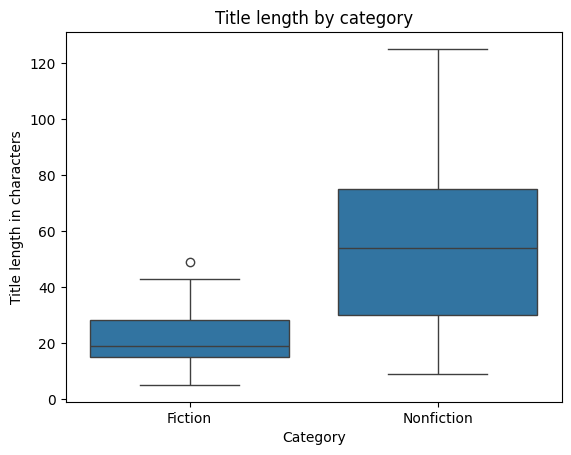

In [7]:
sns.boxplot(
    x="category",
    y="title_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Title length by category")
plt.xlabel("Category")
plt.ylabel("Title length in characters")

plt.show()

In [8]:
df.groupby("category")["title_length"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,64.0,21.750000,10.165300,5.0,15.0,19.0,28.25,49.0
Nonfiction,109.0,54.614679,27.690053,9.0,30.0,54.0,75.00,125.0


In [9]:
print((df[df["category"] == "Nonfiction"]["title_length"] > 49).sum())

64


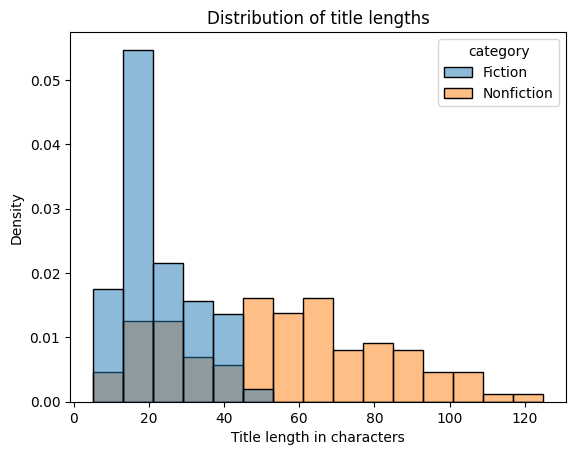

In [31]:
sns.histplot(
    data=df,
    x="title_length",
    hue="category",
    bins=15,
    stat="density",
    common_norm=False
)

plt.title("Distribution of title lengths")
plt.xlabel("Title length in characters")
plt.ylabel("Density")
plt.show()


#### Printing Book with smallest and largest title

In [11]:
df[(df["category"] == "Fiction") & (df["title_length"] > 45)]["title"].iloc[0]

'The Murder That Never Was (Forensic Instincts #5)'

In [12]:
df[(df["category"] == "Nonfiction") & (df["title_length"] >= 125)]["title"].iloc[0]

'10% Happier: How I Tamed the Voice in My Head, Reduced Stress Without Losing My Edge, and Found Self-Help That Actually Works'

In [13]:
df[(df["category"] == "Fiction") & (df["title_length"] <= 5)]["title"].iloc[0]

'Shtum'

In [14]:
df[(df["category"] == "Nonfiction") & (df["title_length"] <=9)]["title"].iloc[0]

'Gratitude'

### Book Description Analysis


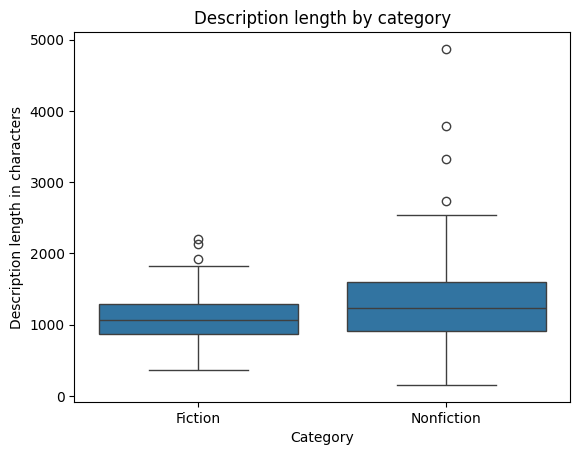

In [15]:
sns.boxplot(
    x="category",
    y="description_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Description length by category")
plt.xlabel("Category")
plt.ylabel("Description length in characters")

plt.show()

In [16]:
df.groupby("category")["description_length"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,64.0,1092.875000,380.520925,364.0,876.0,1066.5,1287.5,2200.0
Nonfiction,109.0,1319.697248,682.414715,155.0,905.0,1240.0,1600.0,4870.0


#### Printing Book with smallest and largest Description


In [17]:
columns = [
    "title",
    "category",
    "description_length",
    "book_url"
]

sorted_books = df.sort_values("description_length")

In [18]:
shortest_book = sorted_books.iloc[0]
longest_book = sorted_books.iloc[-1]

In [19]:
print("SHORTEST DESCRIPTION")
print("Title:", shortest_book["title"])
print("URL:", shortest_book["book_url"])
print("Category:", shortest_book["category"])
print(shortest_book["description"])

SHORTEST DESCRIPTION
Title: Smarter Faster Better: The Secrets of Being Productive in Life and Business
URL: https://books.toscrape.com/catalogue/smarter-faster-better-the-secrets-of-being-productive-in-life-and-business_543/index.html
Category: Nonfiction
A new book that explores the science of productivity, and why, in today’s world, managing how you think—rather than what you think—can transform your life.


In [30]:
print("LONGEST DESCRIPTION")
print("Title:", longest_book["title"])
print("URL:", longest_book["book_url"])
print("Category:", longest_book ["category"])
print(longest_book["description"])

LONGEST DESCRIPTION
Title: Buying In: The Secret Dialogue Between What We Buy and Who We Are
URL: https://books.toscrape.com/catalogue/buying-in-the-secret-dialogue-between-what-we-buy-and-who-we-are_670/index.html
Category: Nonfiction
“Fascinating … A compelling blend of cultural anthropology and business journalism.” — Andrea Sachs, Time Magazine “An often startling tour of new cultural terrain.” — Laura Miller, Salon “Marked by meticulous research and careful conclusions, this superbly readable book confirms New York Times journalist Walker as an expert on consumerism. … [A] thoughtful and unhurried investigation into consumerism that pushes the analysis to the maximum…” — Publisher’s Weekly (starred review) Brands are dead. Advertising no longer works. Weaned on TiVo, the Internet, and other emerging technologies, the short-attention-span generation has become immune to marketing. Consumers are “in control.” Or so we’re told.In Buying In, New York Times Magazine “Consumed” columnis

### Book Cover Photo Analysis


In [21]:
from PIL import Image
import numpy as np

In [22]:
widths = []
heights = []
brightness = []

for image_path in df["image_path"]:
    with Image.open(image_path) as image:
        widths.append(image.width)
        heights.append(image.height)

        gray_image = image.convert("L")
        pixels = np.array(gray_image)

        brightness.append(pixels.mean())

df["cover_width"] = widths
df["cover_height"] = heights

df["cover_ratio"] = df["cover_width"] / df["cover_height"]
df["cover_brightness"] = brightness

In [23]:
df.head(2)

,title,category,book_url,image_url,description,image_path,title_description,title_length,description_length,cover_width,cover_height,cover_ratio,cover_brightness
0,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,Title: Private Paris (Private #10) Description...,27,747,100,155,0.645161,121.468581
1,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,"Title: We Love You, Charlie Freeman Descriptio...",28,1107,102,154,0.662338,85.812198


In [24]:
df.groupby("category")[ ["cover_ratio", "cover_brightness"]].describe()

cover_ratio                                                    \
                 count      mean       std       min       25%       50%   
category                                                                   
Fiction           64.0  0.656603  0.020277  0.600000  0.651613  0.660201   
Nonfiction       109.0  0.678646  0.062748  0.564935  0.655844  0.662338   

                               cover_brightness                         \
                 75%       max            count        mean        std   
category                                                                 
Fiction     0.665595  0.709677             64.0  135.182433  53.388435   
Nonfiction  0.670968  1.096774            109.0  148.268211  60.803322   

                                                                       
                  min         25%         50%         75%         max  
category                                                               
Fiction     10.144253   91.234828  145.103435  180.443823  245.565015  
Nonfiction  20.381784  102.134637  153.972797  192.807702  246.476344

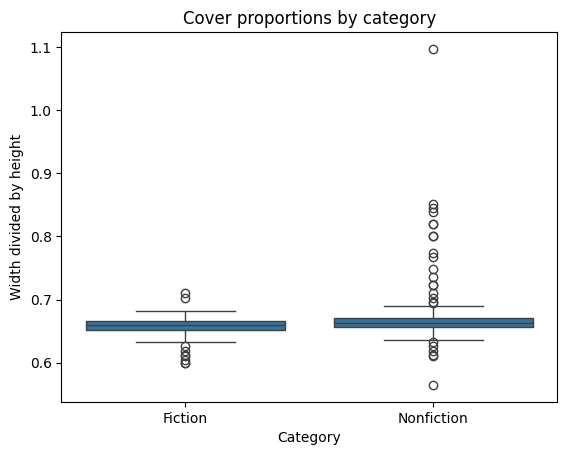

In [25]:
sns.boxplot(
    x="category",
    y="cover_ratio",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Cover proportions by category")
plt.xlabel("Category")
plt.ylabel("Width divided by height")
plt.show()

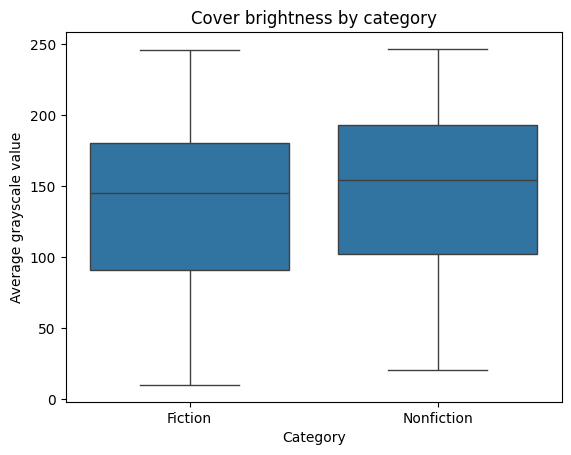

In [26]:
sns.boxplot(
    x="category",
    y="cover_brightness",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Cover brightness by category")
plt.xlabel("Category")
plt.ylabel("Average grayscale value")

plt.show()